In [23]:
import pandas as pd

df = pd.read_csv("insurance_data.csv")
df.head()

,age,bought_insurance
0,22,0
1,25,0
2,47,1
3,52,0
4,46,1


**Visualize the data before train to chose apropriate algorithm**

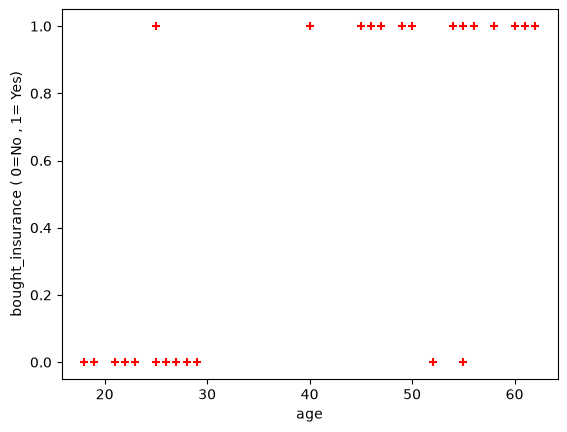

In [24]:
import matplotlib.pyplot as plt

plt.scatter(df["age"], df["bought_insurance"],
marker='+', color='red')

plt.xlabel('age')
plt.ylabel('bought_insurance ( 0=No , 1= Yes)')
plt.show()

In [34]:
from sklearn.model_selection import  train_test_split

X=df[['age']]
y= df['bought_insurance']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_test.head()


,age
8,62
13,29
9,61
21,26
0,22


In [35]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [41]:
y_pred= model.predict(X_test)
y_pred

array([1, 0, 1, 0, 0, 0])

In [45]:
print(model.coef_)
print(model.intercept_)

[[0.11307708]]
[-4.15311919]


In [46]:
y_predicted = model.predict(X_test)
print("Predictions:", y_predicted)
print("Actual:     ", y_test.values)

Predictions: [1 0 1 0 0 0]
Actual:      [1 0 1 0 0 0]


In [49]:
model.predict([[20]])

c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

**Evaluate Model Accuracy and Probabilities**

**predict_proba means:**

Instead of just giving a hard yes/no (1 or 0), predict_proba gives you the confidence percentage for both outcomes.

```Instead of just giving a hard yes/no (1 or 0), predict_proba gives you the confidence percentage for both outcomes.

Understanding the 2 Columns
Each row in the output represents one person in your X_test:
[
Probability of 0  (Won’t Buy)
,
Probability of 1 (Will Buy)]
[Probability of 0 (Won’t Buy),Probability of 1 (Will Buy)]

Notice that both numbers in each row always add up to 1.0 (100%).
Row-by-Row Breakdown of Your Output
Row 1: [0.054,  0.946]
5.4%
5.4% chance they won't buy (0)
94.6%
94.6% chance they will buy (1)
Model prediction: 1 (very confident!)```

If probability ≥ 0.50 (50%50%) →→ classifies as 1
If probability < 0.50 (50%50%) →→ classifies as 0

In [ ]:
# 1. Model accuracy score on test set
score = model.score(X_test, y_test)
print(f"Model Accuracy: {score * 100:.1f}%")

# 2. Predicted probabilities [P(class=0), P(class=1)]
print("\nPredicted Probabilities:")
print(model.predict_proba(X_test))


Model Accuracy: 100.0%

Predicted Probabilities:
[[0.05428672 0.94571328]
 [0.7055532  0.2944468 ]
 [0.06039333 0.93960667]
 [0.77084966 0.22915034]
 [0.84096469 0.15903531]
 [0.72848723 0.27151277]]


**Predict for custom values & inspect the math (Slope & Intercept)**

In [51]:
# Predict for new custom ages (e.g. 35 and 56)
custom_ages = pd.DataFrame({'age': [35, 56]})
print("Custom Predictions (35, 56):", model.predict(custom_ages))

# Logistic regression formula: y = 1 / (1 + e^-(m*age + b))
print("Coefficient (m / slope):", model.coef_[0][0])
print("Intercept (b):", model.intercept_[0])

Custom Predictions (35, 56): [0 1]
Coefficient (m / slope): 0.1130770810616174
Intercept (b): -4.153119185564763


**Visualize the Sigmoid Curve**

# 📌 Understanding the Sigmoid Function in Logistic Regression

## 1. Why do we need Sigmoid?
In **Linear Regression**, the equation produces a straight line:
$$z = m \cdot X + b$$

- Problem: $z$ can range from $-\infty$ to $+\infty$ (e.g. $-50$, $0.4$, $200$).
- In **Classification**, we need a **probability** between **$0$ and $1$** ($0\%$ to $100\%$).

The **Sigmoid function** acts as a bridge: it takes any number $(-\infty, +\infty)$ and squashes it into a value strictly between **$0$ and $1$**.

---

## 2. Mathematical Formula

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Where:
- $e \approx 2.718$ (Euler's number)
- $z = m \cdot X + b$ (Linear combination of weights and inputs)

Putting them together for Logistic Regression:
$$\text{Probability}(y=1) = \frac{1}{1 + e^{-(m \cdot X + b)}}$$

---

## 3. How the Math Behaves (3 Core Cases)

| Value of $z$ | Behavior of $e^{-z}$ | Sigmoid Result $\sigma(z)$ | Interpretation |
| :--- | :--- | :--- | :--- |
| **Large positive** (e.g., $+10$) | $e^{-10} \approx 0$ | $\frac{1}{1 + 0} \approx \mathbf{1.0}$ | High confidence $\rightarrow$ Class 1 |
| **Zero** ($z = 0$) | $e^{0} = 1$ | $\frac{1}{1 + 1} = \mathbf{0.5}$ | Threshold / Decision boundary |
| **Large negative** (e.g., $-10$) | $e^{10} \approx 22026$ (huge) | $\frac{1}{1 + \text{huge}} \approx \mathbf{0.0}$ | High confidence $\rightarrow$ Class 0 |

---

## 4. Visual Representation (S-Curve)

```text
Probability (y)
  1.0 |                   .------- (Buys insurance: class 1)
      |                 /
  0.5 |----------------/---------- (Decision boundary: Threshold = 0.5)
      |              /
  0.0 | _______.----               (Does not buy: class 0)
      +----------------------------
                    Feature (X, e.g., Age)
```

---

## 5. Decision Rule
- If $\sigma(z) \ge 0.5 \implies$ Class **$1$** (e.g., buys insurance)
- If $\sigma(z) < 0.5 \implies$ Class **$0$** (e.g., does not buy insurance)

c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


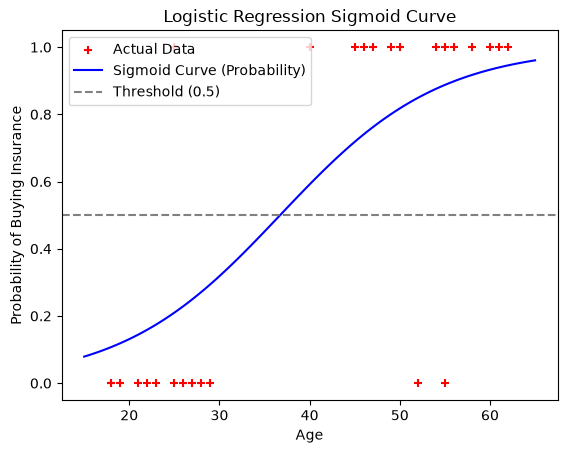

In [52]:
import numpy as np

# 1. Scatter plot of actual data
plt.scatter(df['age'], df['bought_insurance'], marker='+', color='red', label='Actual Data')

# 2. Generate smooth range of ages from 15 to 65
ages_range = np.linspace(15, 65, 100).reshape(-1, 1)

# 3. Predict probabilities for this range
probabilities = model.predict_proba(ages_range)[:, 1]

# 4. Plot the Sigmoid curve
plt.plot(ages_range, probabilities, color='blue', label='Sigmoid Curve (Probability)')
plt.axhline(0.5, color='gray', linestyle='--', label='Threshold (0.5)')

plt.xlabel('Age')
plt.ylabel('Probability of Buying Insurance')
plt.title('Logistic Regression Sigmoid Curve')
plt.legend()
plt.show()